In [1]:
%load_ext autoreload
%autoreload 2

from kontext.visualization import plot_sample_heatmap,plot_dataset_rank_dotplot,get_figs,plot_metric_vs_nobs,plot_boxplots,space_plot,harmonize_target_colors
from kontext.data import get_dataset_info,load_adata
from kontext.utils import format_key,format_value,benchmark_path,run_benchmark_wrapper,run_benchmark

from benchmark.load_data import get_dataset_info


import pandas as pd 
import submitit
import json
import matplotlib.pyplot as plt

plt.rcParams['figure.facecolor'] = '#fcf8f500'
plt.rcParams['axes.facecolor'] = '#fcf8f500'

from itables import init_notebook_mode
init_notebook_mode(all_interactive=True)

ImportError: cannot import name 'plot_sample_heatmap' from 'kontext.visualization' (/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext_project/.venv/lib/python3.12/site-packages/kontext/visualization.py)

In [5]:
ZESTA = [['ZESTA', 'zf3_1'], ['ZESTA', 'zf5_10'], ['ZESTA', 'zf10_14'], ['ZESTA', 'zf12_8'], ['ZESTA', 'zf12_9'], ['ZESTA', 'zf18_7'], 
         ['ZESTA', 'zf18_8'], ['ZESTA', 'zf18_9'], ['ZESTA', 'zf24_4'], ['ZESTA', 'zf24_7'], ['ZESTA', 'zf24_9'], ['ZESTA', 'zf24_10']]
ARTISTA = [['ARTISTA', '2DPI_1'], ['ARTISTA', '5DPI_2'], ['ARTISTA', '10DPI_3'], ['ARTISTA', '15DPI_1'], 
           ['ARTISTA', '20DPI_2'], ['ARTISTA', '30DPI'], ['ARTISTA', '60DPI']]
MOSTA = [['MOSTA', 'E9.5_E1S1'], ['MOSTA', 'E10.5_E1S1'], ['MOSTA', 'E11.5_E1S1'], 
         ['MOSTA', 'E12.5_E1S1'], ['MOSTA', 'E14.5_E1S1'], ['MOSTA', 'E16.5_E1S1']]
MBA = [['MBA', 'C57BL6J_1_053'], ['MBA', 'C57BL6J_1_082'], ['MBA', 'C57BL6J_1_117'], 
       ['MBA', 'C57BL6J_1_111'], ['MBA', 'C57BL6J_1_113']]

STEREO = ZESTA + ARTISTA + MOSTA 
MERFISH = MBA 
BENCHMARK = STEREO + MERFISH

for dataset,sample in BENCHMARK :
    info = get_dataset_info()[dataset][sample]
    print(dataset,sample,info['n_obs'],info['n_clusters'])




ZESTA zf3_1 1167 3
ZESTA zf5_10 563 7
ZESTA zf10_14 1231 8
ZESTA zf12_8 2081 11
ZESTA zf12_9 2588 11
ZESTA zf18_7 3475 14
ZESTA zf18_8 3048 14
ZESTA zf18_9 5935 14
ZESTA zf24_4 5271 19
ZESTA zf24_7 6318 18
ZESTA zf24_9 4708 17
ZESTA zf24_10 5968 18
ARTISTA 2DPI_1 7668 18
ARTISTA 5DPI_2 8178 17
ARTISTA 10DPI_3 10002 18
ARTISTA 15DPI_1 8996 18
ARTISTA 20DPI_2 11319 20
ARTISTA 30DPI 9252 17
ARTISTA 60DPI 10964 16
MOSTA E9.5_E1S1 5913 12
MOSTA E10.5_E1S1 18408 13
MOSTA E11.5_E1S1 30124 19
MOSTA E12.5_E1S1 51365 23
MOSTA E14.5_E1S1 102519 26
MOSTA E16.5_E1S1 121767 25
MBA C57BL6J_1_053 34126 {'ccf_region_name': 77, 'major_brain_region': 9, 'tissue': 9, 'cell_type': 19}
MBA C57BL6J_1_082 42117 {'ccf_region_name': 170, 'major_brain_region': 10, 'tissue': 10, 'cell_type': 22}
MBA C57BL6J_1_117 22862 {'ccf_region_name': 59, 'major_brain_region': 6, 'tissue': 6, 'cell_type': 21}
MBA C57BL6J_1_111 35171 {'ccf_region_name': 89, 'major_brain_region': 8, 'tissue': 8, 'cell_type': 20}
MBA C57BL6J_1_1

## Benchmark stereo-seq datasets 

In [3]:


min_seed,max_seed = 0,100
seeds = range(min_seed,max_seed)
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  


methods = {
'Kontext':{'additional_info':{'name':'Kontext'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':1},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'large2svg'}},
'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR gmm'},'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}


total_torun = 0
total_done = 0
total_missing = 0
total = 0
results = {}


for dataset,sample in STEREO[:]:
    print(dataset,sample)
    print(dataset,sample,get_dataset_info()[dataset][sample]['n_obs'])
    data = {'dataset':dataset,'sample':sample}
    results[f'{dataset}+{sample}'] = []
    for name,param0 in methods.items():    
            matrix = param0['matrix']
            executor_params = {
                        'slurm_partition':'common' if matrix in ['Kontext','BANKSY'] else 'ml4ig_gpu',
                        'slurm_cpus_per_task':1,
                        'slurm_array_parallelism':100,
                        'slurm_mem':('50G' if dataset=='MOSTA' else '5G') if matrix in ['Kontext','BANKSY'] else ('200G' if dataset=='MOSTA' else '15G'),#get_needed_mem(dataset,sample,step='all'),
                        'timeout_min':600,
                        'slurm_job_name':f'{name}_{sample}',
                        'slurm_srun_args':["--cpu-bind=none",'--nice=19'],
                        'slurm_gres': None if matrix in ['Kontext','BANKSY'] else 'gpu:1',
                        }

            params_all = []
            params_done = []
            params_missing = []

            for seed in seeds:


                param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                param['data'] = data
                if 'seed' in param['embedding']:
                    param['embedding']['seed'] = seed
                if 'seed' in param['clustering']:
                    param['clustering']['seed'] = seed
                signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['clustering']}.items() if v is not None and k!='additional_info')
                path = benchmark_path(data)
                p = path / f'{signature}.json'
                params_all += [param]
                
                if not p.exists():
                    params_missing += [param]
                else:
                    params_done += [param]
                    with open(p, "r") as f:
                        out = json.load(f)
                    results[f'{dataset}+{sample}'] += [out]


#### Uncomment to run benchmark locally in the loop

                # run_benchmark_wrapper(param)
                # run_example(**param)

####

            executor = submitit.AutoExecutor(folder=f"logs3/benchmark_{dataset}_{sample}/{matrix}/")
            executor.update_parameters(**executor_params ) 

            params_torun = params_all if run_all else params_missing
            n_torun = len(params_all) if run_all else len(params_missing)
            n_done = len(params_done)
            n_missing = len(params_missing)
            total_torun += n_torun
            total_done += n_done
            total_missing += n_missing

            print(f'{dataset} {sample} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')

#### Uncomment to submit jobs with submitit

            # print(executor_params)
            # if len(params_torun)>0:
            #     jobs = executor.map_array(run_benchmark_wrapper,params_torun)

#####
print(results)


ZESTA zf3_1
ZESTA zf3_1 1167
ZESTA zf3_1 Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=100 total_missing=0
ZESTA zf3_1 BANKSY to_run=0 done=100 missing=0 total_torun=0 total_done=200 total_missing=0
ZESTA zf3_1 SEDR to_run=0 done=100 missing=0 total_torun=0 total_done=300 total_missing=0
ZESTA zf3_1 GraphST to_run=0 done=100 missing=0 total_torun=0 total_done=400 total_missing=0
ZESTA zf5_10
ZESTA zf5_10 563
ZESTA zf5_10 Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=500 total_missing=0
ZESTA zf5_10 BANKSY to_run=0 done=100 missing=0 total_torun=0 total_done=600 total_missing=0
ZESTA zf5_10 SEDR to_run=0 done=100 missing=0 total_torun=0 total_done=700 total_missing=0
ZESTA zf5_10 GraphST to_run=0 done=100 missing=0 total_torun=0 total_done=800 total_missing=0
ZESTA zf10_14
ZESTA zf10_14 1231
ZESTA zf10_14 Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=900 total_missing=0
ZESTA zf10_14 BANKSY to_run=0 done=100 missing=0 total_torun=0 total_done

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [4]:

min_seed,max_seed = 0,100
seeds = range(min_seed,max_seed)
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  
annotations = ['ccf_region_name','tissue','cell_type']

methods = {
'Kontext a=0':{'additional_info':{'name':'a=0'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'Kontext a=0.1':{'additional_info':{'name':'a=0.1'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.1},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'Kontext a=0.2':{'additional_info':{'name':'a=0.2'},'matrix':'Kontext', 'embedding':{"sigma_e":1, "snn":20, 'alpha':0.2},'clustering':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'xenium'}},
'Kontext a=0.3':{'additional_info':{'name':'a=0.3'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.3},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'Kontext a=0.4':{'additional_info':{'name':'a=0.4'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.4},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'Kontext a=0.5':{'additional_info':{'name':'a=0.5'},'matrix':'Kontext', 'embedding':{"sigma_e":1, "snn":20, 'alpha':0.5},'clustering':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'xenium'}},
'Kontext a=1':{'additional_info':{'name':'a=1'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':1},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'Kontext a=2':{'additional_info':{'name':'a=2'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':2},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'Kontext a=3':{'additional_info':{'name':'a=3'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':3},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'Kontext a=10':{'additional_info':{'name':'a=10'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':10},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'SEDR':{'additional_info':{'name':'SEDR gmm'},'matrix':'SEDR',              'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'SEDR'}},
'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}


total_torun = 0
total_done = 0
total_missing = 0
total = 0
# results = {}
nerr = 0
for annotation in  annotations:
    for dataset,sample in MERFISH:
        print(dataset,sample,annotation)
        data = {'dataset':dataset,'sample':sample,'annotation':annotation}
        results[f'{dataset}_{annotation}+{sample}'] = []
        for name,param0 in methods.items():    
            matrix = param0['matrix'] 
            executor_params = {
                        'slurm_partition':'common' if matrix in ['Kontext','BANKSY'] else 'ml4ig_gpu',
                        'slurm_cpus_per_task':1,
                        'slurm_array_parallelism':100,
                        'slurm_mem':'5G' if matrix in ['Kontext','BANKSY'] else '80G',#get_needed_mem(dataset,sample,step='all'),
                        'timeout_min':180,
                        'slurm_job_name':f'{name}_{sample}_{annotation}',
                        'slurm_srun_args':["--cpu-bind=none"],
                        'slurm_gres': None if matrix in ['Kontext','BANKSY'] else 'gpu:1',
                        }

            params_all = []
            params_done = []
            params_missing = []
            for seed in seeds:
                param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                param['data'] = data
                if 'seed' in param['embedding']:
                    param['embedding']['seed'] = seed
                if 'seed' in param['clustering']:
                    param['clustering']['seed'] = seed

                signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['clustering']}.items() if v is not None and k!='additional_info')
                path = benchmark_path(data)
                p = path / f'{signature}.json'
                params_all += [param]
                
                if not p.exists():
                    params_missing += [param]
                else:
                    params_done += [param]
                    try:
                        with open(p, "r") as f:
                            out = json.load(f)
                    except:
                        print(p)
                        nerr+=1
                    results[f'{dataset}_{annotation}+{sample}'] += [out]

#### Uncomment to run benchmark locally in the loop
    
                # run_benchmark_wrapper(param)

####



            executor = submitit.AutoExecutor(folder=f"logs3/benchmark_{dataset}_{sample}_{annotation}/{name}/")
            executor.update_parameters(**executor_params ) 

            params_torun = params_all if run_all else params_missing
            n_torun = len(params_all) if run_all else len(params_missing)
            n_done = len(params_done)
            n_missing = len(params_missing)
            total_torun += n_torun
            total_done += n_done
            total_missing += n_missing
            print(f'err{nerr} {dataset} {sample} {annotation} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')



#### Uncomment to submit jobs with submitit

            # if len(params_torun)>0:
            #     jobs = executor.map_array(run_benchmark_wrapper,params_torun)
                
#####

print(results)



MBA C57BL6J_1_053 ccf_region_name
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=100 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=200 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=300 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=400 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=500 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=600 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=700 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=800 total_missing=0
err0 M

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [5]:
results_heatmap = {}
results_heatmap_stereo = {}
results_heatmap_merfish = {}
for dataset,sample in BENCHMARK:
    for annotation in annotations:
        print(sample,annotation)
        if dataset == 'MBA':
            ds = f'{dataset}_{annotation}+{sample}'
        else:
            ds = f'{dataset}+{sample}'
        if ds not in results:
            continue

        res = results[ds]
        new_res = []
        new_res_stereo = []
        new_res_merfish = []

        for run in res:
            i = run.copy()
            i['name'] = str(i['name']).replace('large2svg pp','Kontext').replace(' gmm','')#.replace('a=1','Kontext')
            i['name'] = str(i['name']).replace(' LR','').replace(' gmm','')#.replace('a=1','Kontext')
            i['dataset'] = f'{dataset} {annotation}'.replace('MBA_','MBA ')
            if 'alpha' in i and dataset=='MBA':
                i['name'] = 'Kontext' if (annotation == 'ccf_region_name' and i['alpha']==0) or (annotation == 'tissue' and i['alpha']==0.2) or (annotation == 'cell_type' and i['alpha']==10) else 'other'
                # i['name'] = 'Kontext' if i['alpha'] == 1 else 'other' #(annotation == 'ccf_region_name' and i['alpha']==0) or (annotation == 'tissue' and i['alpha']==0.2) or (annotation == 'cell_type' and i['alpha']==10) else 'other'
            if i['name'] != 'other':
                new_res += [i]
                if 'MBA' in i['dataset']: 
                    new_res_merfish += [i]
                else: 
                    new_res_stereo += [i]

        results_heatmap[ds] = new_res
        results_heatmap_stereo[ds] = new_res_stereo
        results_heatmap_merfish[ds] = new_res_merfish

# print(results[f'{dataset}+{sample}_{annotation}'])

zf3_1 ccf_region_name
zf3_1 tissue
zf3_1 cell_type
zf5_10 ccf_region_name
zf5_10 tissue
zf5_10 cell_type
zf10_14 ccf_region_name
zf10_14 tissue
zf10_14 cell_type
zf12_8 ccf_region_name
zf12_8 tissue
zf12_8 cell_type
zf12_9 ccf_region_name
zf12_9 tissue
zf12_9 cell_type
zf18_7 ccf_region_name
zf18_7 tissue
zf18_7 cell_type
zf18_8 ccf_region_name
zf18_8 tissue
zf18_8 cell_type
zf18_9 ccf_region_name
zf18_9 tissue
zf18_9 cell_type
zf24_4 ccf_region_name
zf24_4 tissue
zf24_4 cell_type
zf24_7 ccf_region_name
zf24_7 tissue
zf24_7 cell_type
zf24_9 ccf_region_name
zf24_9 tissue
zf24_9 cell_type
zf24_10 ccf_region_name
zf24_10 tissue
zf24_10 cell_type
2DPI_1 ccf_region_name
2DPI_1 tissue
2DPI_1 cell_type
5DPI_2 ccf_region_name
5DPI_2 tissue
5DPI_2 cell_type
10DPI_3 ccf_region_name
10DPI_3 tissue
10DPI_3 cell_type
15DPI_1 ccf_region_name
15DPI_1 tissue
15DPI_1 cell_type
20DPI_2 ccf_region_name
20DPI_2 tissue
20DPI_2 cell_type
30DPI ccf_region_name
30DPI tissue
30DPI cell_type
60DPI ccf_region_na

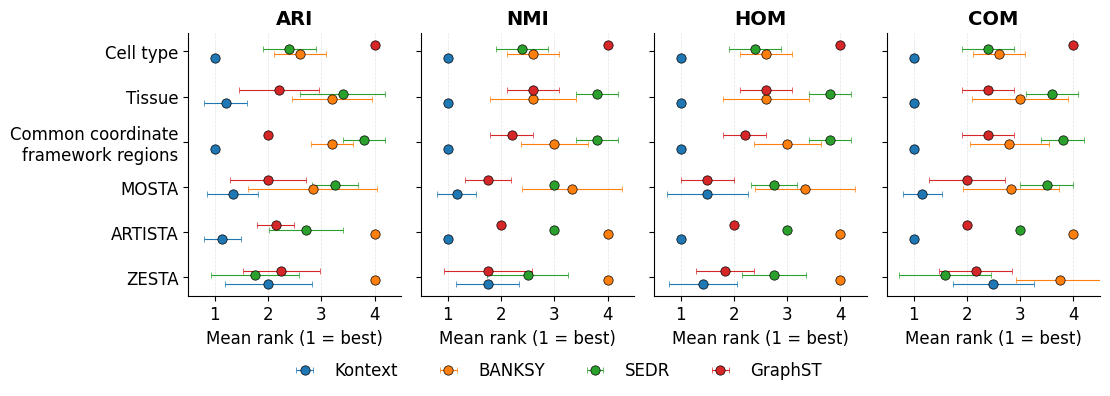

In [10]:
fig,axes,df1 = plot_dataset_rank_dotplot(results_heatmap,metrics=('ARI','NMI','HOM','COM'),fontsize=12)
axes[0].set_yticklabels([tick._text.replace('MBA_','').replace('cell_type','Cell type').replace('tissue','Tissue').replace('ccf_region_name','Common coordinate\nframework regions') 
                         for tick in axes[0].get_yticklabels()],fontsize=12)
plt.tight_layout(rect=[0, 0.08, 1, 1])
# fig.savefig('kontext_project/figures/benchmark/benchmark_1a_ranks.pdf')

ARI
ZESTA+zf3_1 [0.20539425 0.03435684 0.21540663 0.15560329]
ZESTA+zf5_10 [0.12622154 0.08015896 0.25621267 0.16140489]
ZESTA+zf10_14 [0.27741662 0.19591936 0.28182202 0.27427454]
ZESTA+zf12_8 [0.38006834 0.29562946 0.43248201 0.40131036]
ZESTA+zf12_9 [0.34075188 0.31892299 0.40445111 0.37822988]
ZESTA+zf18_7 [0.26478551 0.23877377 0.25386844 0.2591002 ]
ZESTA+zf18_8 [0.25279845 0.15364696 0.23490635 0.24217402]
ZESTA+zf18_9 [0.1743814  0.12557246 0.21297423 0.26782059]
ZESTA+zf24_4 [0.34926454 0.22815919 0.39097426 0.34638682]
ZESTA+zf24_7 [0.41772211 0.23319045 0.3809814  0.37829676]
ZESTA+zf24_9 [0.41826372 0.31754977 0.40400803 0.37234617]
ZESTA+zf24_10 [0.4111716  0.37897793 0.40580419 0.46516075]
ARTISTA+2DPI_1 [0.40080297 0.12330346 0.31818004 0.38288997]
ARTISTA+5DPI_2 [0.40794077 0.1132414  0.31867918 0.378175  ]
ARTISTA+10DPI_3 [0.37162135 0.09477009 0.30136474 0.33869965]
ARTISTA+15DPI_1 [0.37523089 0.20116075 0.282434   0.37059055]
ARTISTA+20DPI_2 [0.47623254 0.17514114 0.

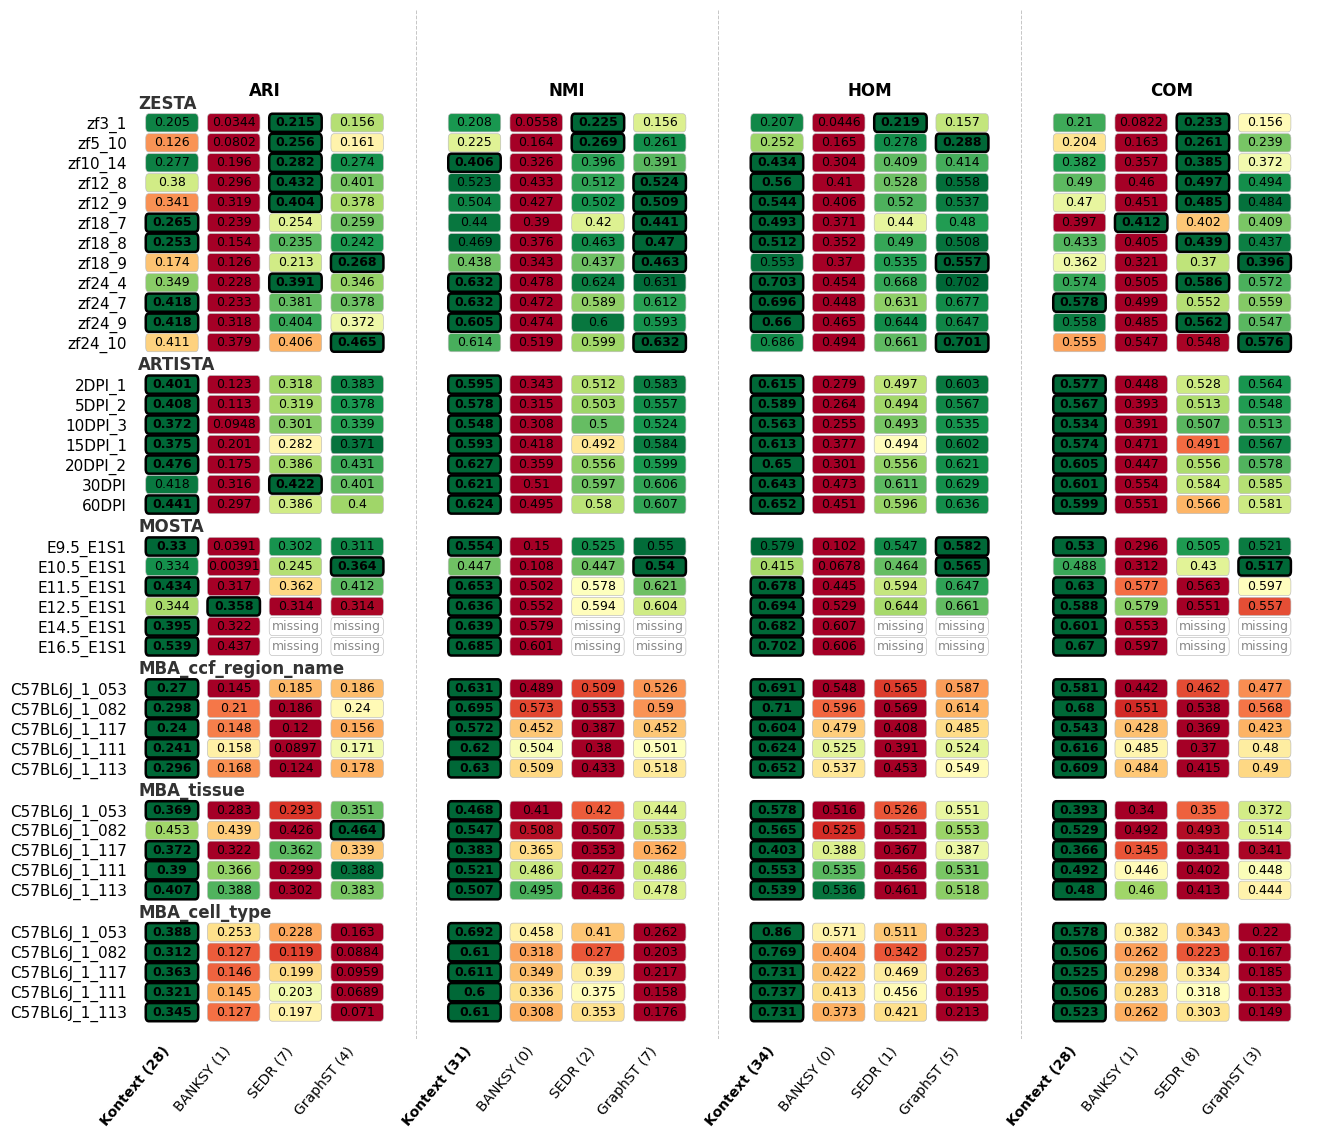

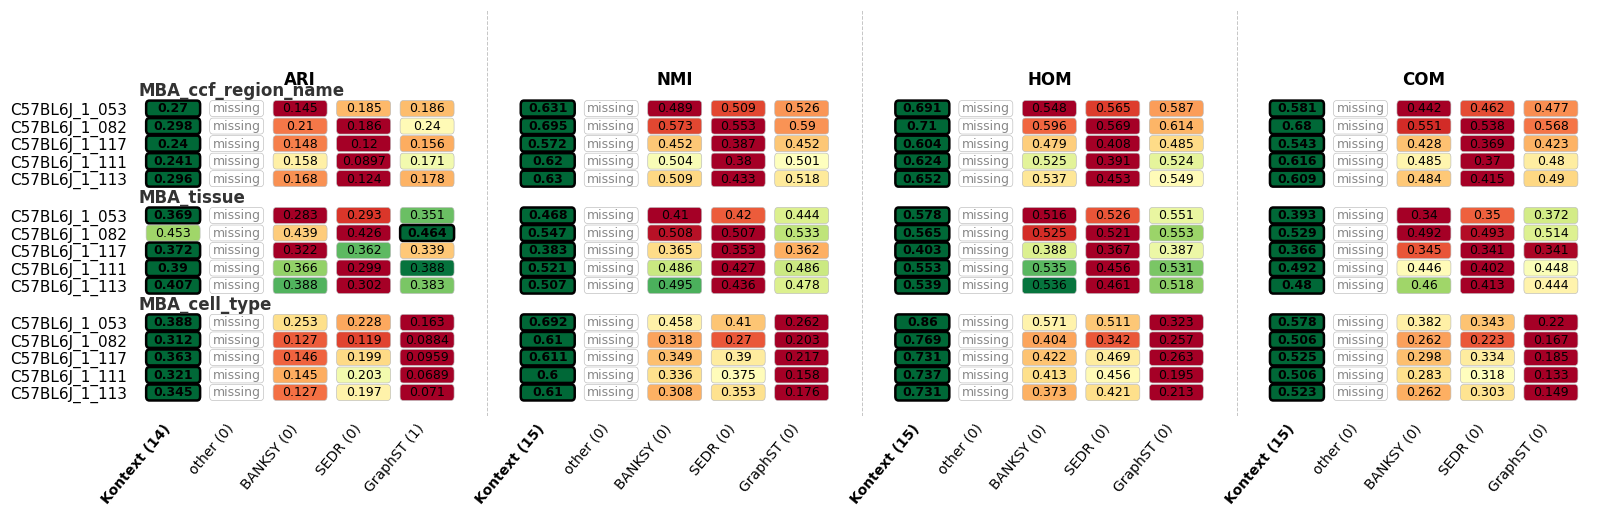

In [ ]:
fig,axes,df2 = plot_sample_heatmap(results_heatmap, metrics = ('ARI','NMI','HOM','COM'), agg='mean', rect_width=0.85, rect_height=0.20,
fontsize_ticks=10,fontsize_scores=9)
fig.tight_layout()

# fig.savefig('kontext_project/figures/benchmark/benchmark_s1_heatmap.pdf')


ARI
MBA_ccf_region_name+C57BL6J_1_053 [0.26979937 0.14508035 0.18533826 0.18621895]
MBA_ccf_region_name+C57BL6J_1_082 [0.29777387 0.21023762 0.18589978 0.24004222]
MBA_ccf_region_name+C57BL6J_1_117 [0.24012051 0.1478537  0.12030814 0.15624577]
MBA_ccf_region_name+C57BL6J_1_111 [0.2413557  0.15788191 0.08966906 0.17082716]
MBA_ccf_region_name+C57BL6J_1_113 [0.29626112 0.16833568 0.12419336 0.17776363]
MBA_tissue+C57BL6J_1_053 [0.36859122 0.28328514 0.29278607 0.35089838]
MBA_tissue+C57BL6J_1_082 [0.45266344 0.43945425 0.42573044 0.46368826]
MBA_tissue+C57BL6J_1_117 [0.37197563 0.32176337 0.3624861  0.33945107]
MBA_tissue+C57BL6J_1_111 [0.39042414 0.36581668 0.29920011 0.38803076]
MBA_tissue+C57BL6J_1_113 [0.40685443 0.3884039  0.30187504 0.38257027]
MBA_cell_type+C57BL6J_1_053 [0.38803833 0.25263564 0.22808372 0.16250788]
MBA_cell_type+C57BL6J_1_082 [0.31203137 0.12715885 0.11892107 0.08841055]
MBA_cell_type+C57BL6J_1_117 [0.36257333 0.14553925 0.19930603 0.09594904]
MBA_cell_type+C57BL

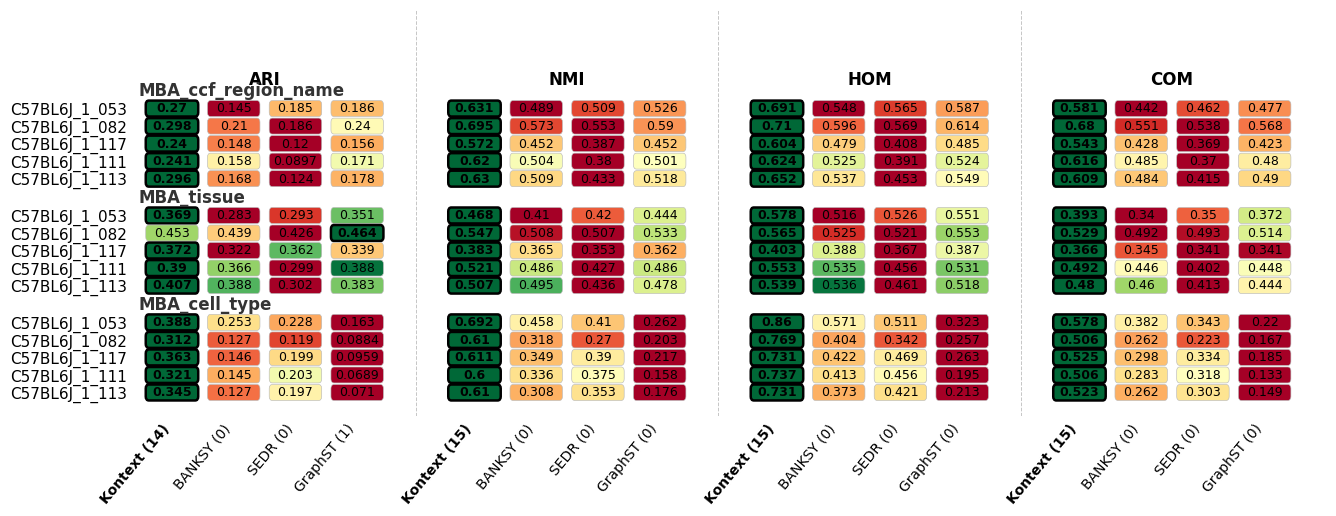

In [82]:
fig,axes,df2 = plot_sample_heatmap(results_heatmap_merfish, metrics = ('ARI','NMI','HOM','COM'), agg='mean', rect_width=0.85, rect_height=0.20,
fontsize_ticks=10,fontsize_scores=9)
fig.tight_layout()

ARI
ZESTA+zf3_1 [ 0.17287427 -0.0007994   0.18854754  0.12666142]
ZESTA+zf5_10 [0.10503884 0.03501261 0.21018626 0.14187243]
ZESTA+zf10_14 [0.25659016 0.1181082  0.2607177  0.25697563]
ZESTA+zf12_8 [0.35866821 0.21253838 0.40173691 0.37439803]
ZESTA+zf12_9 [0.32385984 0.24666906 0.38528532 0.35938126]
ZESTA+zf18_7 [0.25399362 0.18102127 0.24481011 0.24925145]
ZESTA+zf18_8 [0.23328245 0.10275922 0.21599006 0.22098215]
ZESTA+zf18_9 [0.16581503 0.08447062 0.18714566 0.23985889]
ZESTA+zf24_4 [0.33134829 0.20174607 0.36112497 0.33085899]
ZESTA+zf24_7 [0.39412918 0.18636747 0.35304945 0.3573126 ]
ZESTA+zf24_9 [0.39692322 0.27280462 0.3888954  0.35292087]
ZESTA+zf24_10 [0.37693233 0.3160916  0.370948   0.43662966]
ARTISTA+2DPI_1 [0.38077905 0.07418647 0.30095126 0.36366796]
ARTISTA+5DPI_2 [0.3936204  0.06438725 0.30354123 0.3640439 ]
ARTISTA+10DPI_3 [0.35357042 0.06154934 0.2891437  0.32584711]
ARTISTA+15DPI_1 [0.36331994 0.15194841 0.26256764 0.35732889]
ARTISTA+20DPI_2 [0.45782423 0.1292421

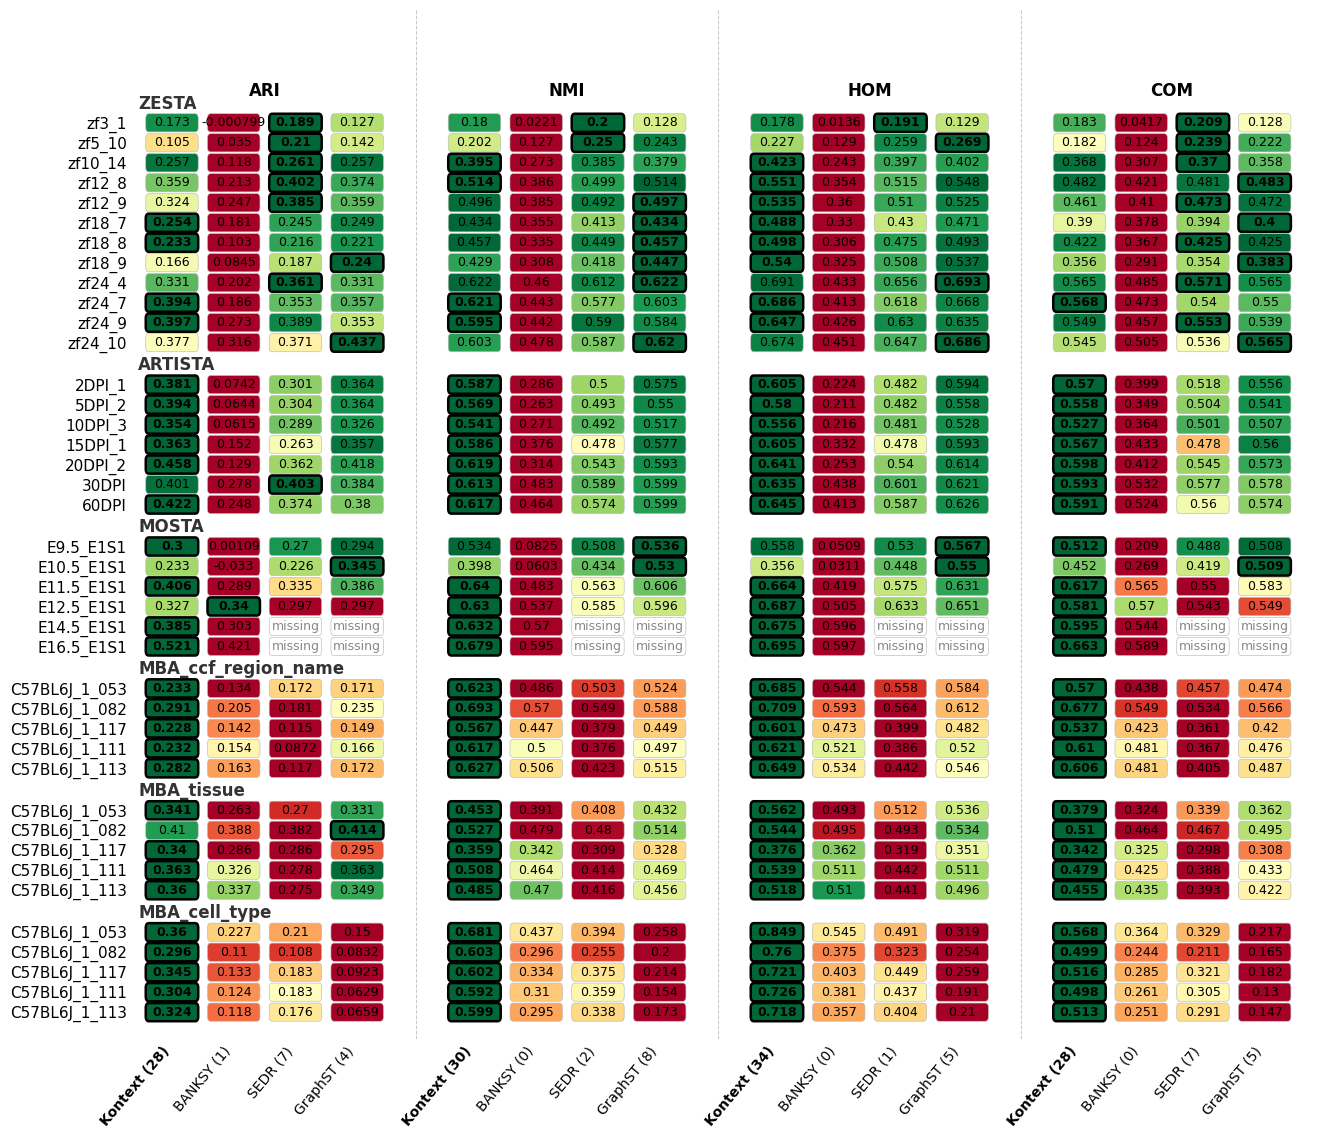

In [79]:
fig,axes,df2 = plot_sample_heatmap(results_heatmap, metrics = ('ARI','NMI','HOM','COM'),
                                   agg='mean-std', rect_width=0.85, rect_height=0.20,
                                #    lower_better=('ARI','NMI','HOM','COM'),
fontsize_ticks=10,fontsize_scores=9)
fig.tight_layout()

embedding_time
[[1167 'BANKSY' 2.2877229166030886]
 [1167 'GraphST' 14.867796120643616]
 [1167 'Kontext' 1.766795542240143]
 [1167 'SEDR' 15.042920982837677]
 [563 'BANKSY' 1.5147545409202576]
 [563 'GraphST' 14.373790166378022]
 [563 'Kontext' 1.6357750725746154]
 [563 'SEDR' 14.886952135562897]
 [1231 'BANKSY' 2.684713370800018]
 [1231 'GraphST' 15.326172909736634]
 [1231 'Kontext' 1.7385871624946594]
 [1231 'SEDR' 15.78319669008255]
 [2081 'BANKSY' 4.15790162563324]
 [2081 'GraphST' 15.482769465446472]
 [2081 'Kontext' 1.8668650913238525]
 [2081 'SEDR' 15.832222492694855]
 [2588 'BANKSY' 5.58370463848114]
 [2588 'GraphST' 15.641630012989044]
 [2588 'Kontext' 1.9473673868179322]
 [2588 'SEDR' 16.374678819179536]
 [3475 'BANKSY' 8.676911585330963]
 [3475 'GraphST' 17.034955234527587]
 [3475 'Kontext' 2.1118433904647826]
 [3475 'SEDR' 17.194555351734163]
 [3048 'BANKSY' 6.271237564086914]
 [3048 'GraphST' 16.59628924846649]
 [3048 'Kontext' 1.982652177810669]
 [3048 'SEDR' 17.042644073

/local/scratch/tmp/ipykernel_1245567/2711124131.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
/local/scratch/tmp/ipykernel_1245567/2711124131.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


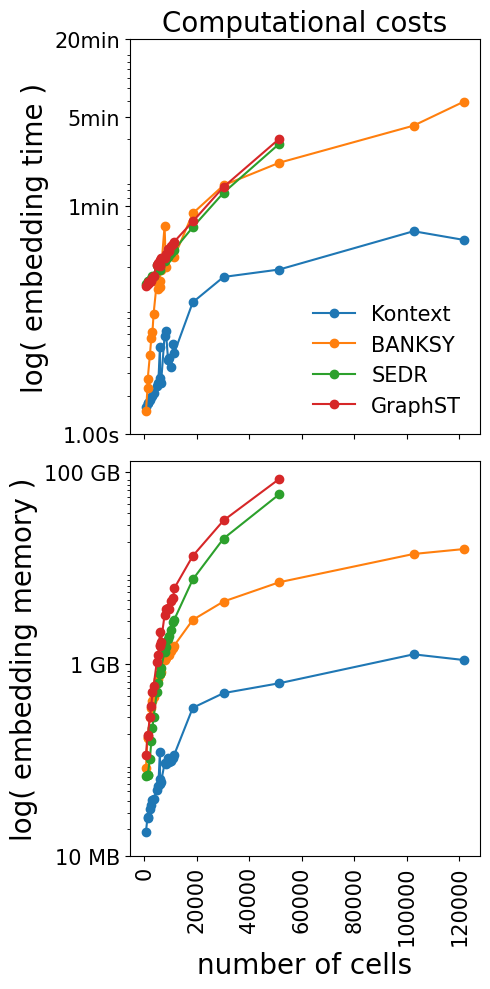

In [73]:
from kontext.utils import format_size,format_time

metrics = ['embedding_time', 'embedding_memory_b']
fig, axes = get_figs(len(metrics),5,5,vert=True)
for ax, met in zip(axes, metrics):
    print(met)
    plot_metric_vs_nobs(results_heatmap, STEREO, met, ax=ax,logy=True,logx=False)
axes[0].set_title('Computational costs',fontsize=20)
axes[1].set_title('',fontsize=20)
axes[0].set_ylabel('log( embedding time )',fontsize=20)
axes[1].set_ylabel('log( embedding memory )',fontsize=20)
axes[0].set_xlabel('',fontsize=15)
axes[1].set_xlabel('number of cells',fontsize=20)
axes[0].set_xticklabels([])
axes[1].set_xticklabels(ax.get_xticklabels(), rotation='vertical', fontsize=15) 
axes[1].set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=15) 

times = [1,60,60*5,20*60]
memory_sizes = [10*1024*1024,1024*1024*1024,1024**3*100]

axes[0].set_yticks(times)
axes[0].set_yticklabels([format_time(time).split('-')[0] for time in times],fontsize=15)
axes[1].set_yticks(memory_sizes)
axes[1].set_yticklabels([format_size(memory).replace('.00','') for memory in memory_sizes],fontsize=15)
# axes[0].set_yticklabels([]ax.get_yticklabels(), rotation='horizontal', fontsize=15) 

axes[1].get_legend().remove()

fig.tight_layout()
# fig.savefig('kontext_project/figures/benchmark/benchmark_1b_time_memory.pdf')


... storing 'sample' as categorical
... storing 'sample' as categorical


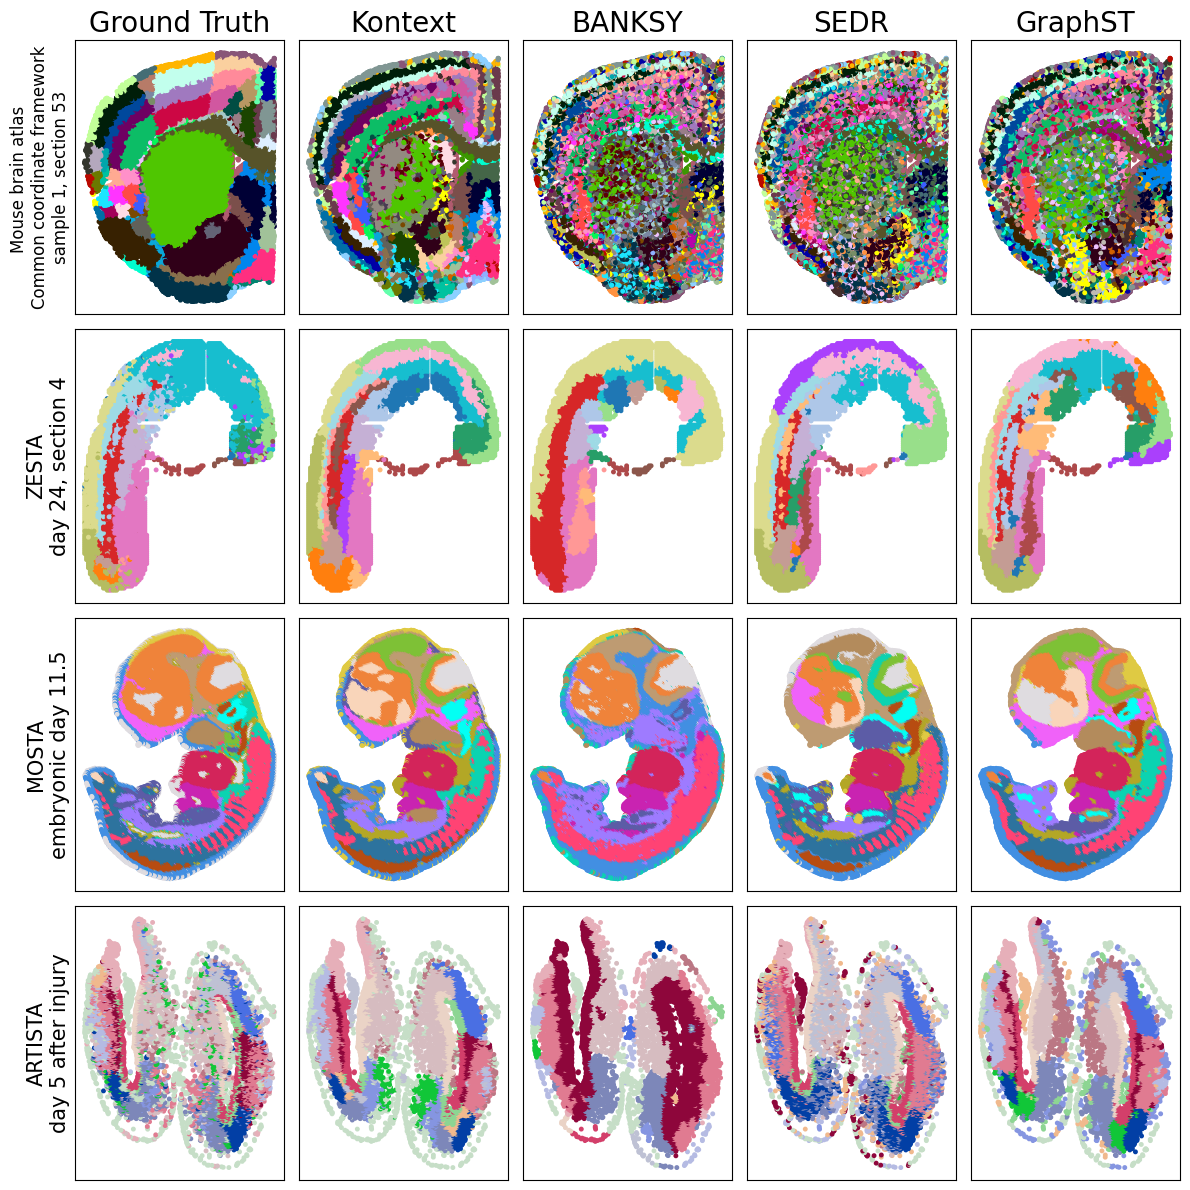

In [19]:
seed = 0
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  


methods = {
# 'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR'},'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
# 'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST'},'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':None}},
# 'Kontext mclust':{'matrix':'Kontext','additional_info':{'name':'Kontext mclust'},'embedding':{"sigma_e":0.3, "snn":20, 'alpha':1},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':'large2svg'}},
# 'BANKSY mclust':{'matrix':'BANKSY','additional_info':{'name':'BANKSY mclust'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'Kontext':{'matrix':'Kontext','additional_info':{'name':'large2svg pp'},'embedding':{"sigma_e":1, "snn":20, 'alpha':1},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'large2svg'}},
'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR gmm'},'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}





TO_SHOW = (
           ['MBA','C57BL6J_1_053'],
     ['ZESTA','zf24_4'],['MOSTA','E11.5_E1S1'],['ARTISTA','5DPI_2'],
           )
annotation = 'ccf_region_name'


ncols = len(methods)+1
nrows = len(TO_SHOW)
fig,axes = plt.subplots(nrows=nrows,ncols=ncols,figsize=(12,12))
i=-1
for dataset,sample in TO_SHOW:
    data = {'dataset':dataset,'sample':sample,'annotation':annotation} if dataset == 'MBA' else {'dataset':dataset,'sample':sample} 
    ylabel =f'{dataset} {sample.split('_')[-1]}' if dataset == 'MBA' else f'{dataset} {sample.split('_')[0]}'
    ylabel = ylabel.replace(' zf24','\nday 24, section 4')
    ylabel = ylabel.replace(' E11.5','\nembryonic day 11.5')
    ylabel = ylabel.replace(' 5DPI','\nday 5 after injury')
    ylabel = ylabel.replace('MBA','Mouse brain atlas \nCommon coordinate framework')
    ylabel = ylabel.replace(' 053','\nsample 1, section 53')
    
    adata = load_adata(**data)


    i+=1
    j=0
    ax = axes[i,j]
    space_plot(adata,'annotation',s=50,ax=ax)
    ax.get_legend().remove()
    if i!=0:
        ax.set_title('')
    else:
        ax.set_title(f'Ground Truth',fontsize=20)
    ax.set_xlabel('')
    ax.set_ylabel(f'{ylabel}',fontsize=12 if dataset == 'MBA' else 15)

    for name,param0 in methods.items():    
            matrix = param0['matrix']
            param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
            if dataset == 'MBA' and name=='Kontext':
                param['preprocessing']={"preprocessing":"xenium"}
                param['embedding']={"sigma_e":1, "snn":20, 'alpha':0}

            param['data'] = data
            signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['clustering']}.items() if v is not None and k!='additional_info')
            path = benchmark_path(data)
            p = path / f'{signature}.json'
            pclust = path / f'{signature}_clustering.csv'

            j+=1
            ax = axes[i,j]
            if pclust.exists():
                df = pd.read_csv(pclust,index_col=0)
                adata.obs[name] = df['clustering']
                harmonize_target_colors(adata,col_target=name)
                space_plot(adata,name,s=50,ax=ax)
                ax.get_legend().remove()
                ax.set_xlabel('')
                ax.set_ylabel('')
                if i != 0:
                    ax.set_title('')
                if i == 0:
                    ax.set_title(f'{name}',fontsize=20)
fig.tight_layout()

plt.show()
# fig.savefig('kontext_project/figures/benchmark/benchmark_1c_space_plots.pdf')
print(results)


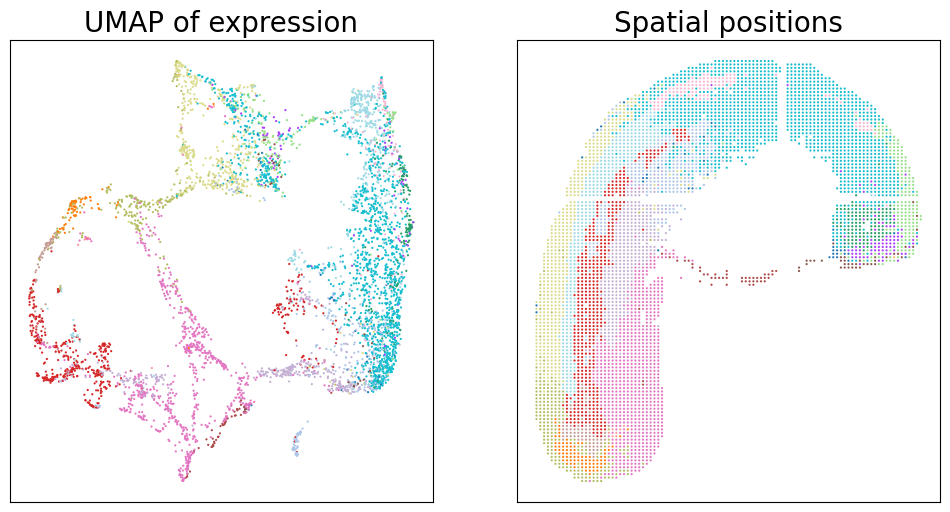

... storing 'sample' as categorical


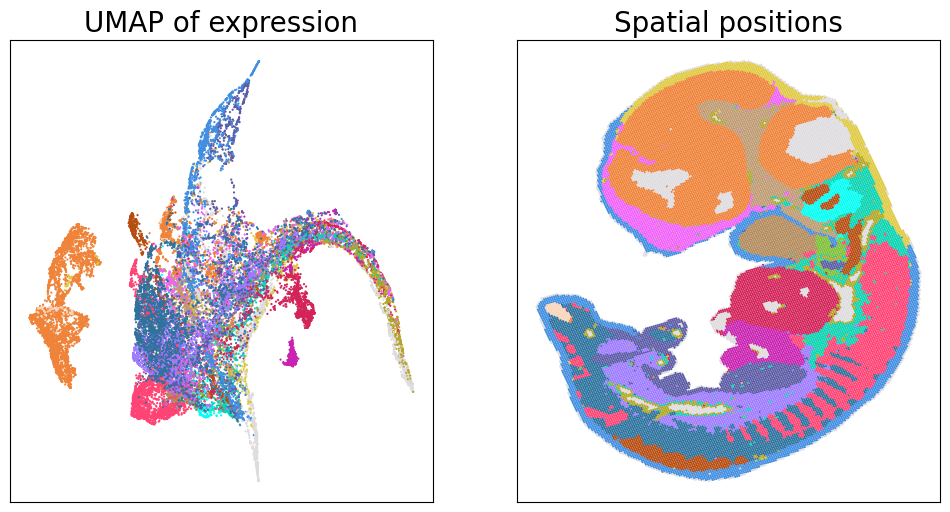

... storing 'sample' as categorical


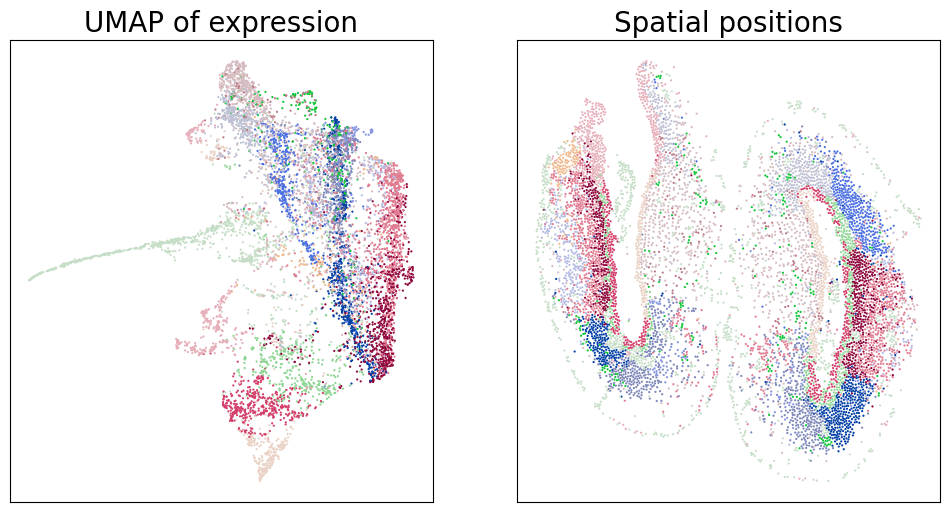

In [16]:
from benchmark.load_data import load_adata

from kontext.utils import pca_of_mat

from umap.umap_ import UMAP
from kontext.visualization import umap_plot
from kontext.utils import pca_on_adata

TO_SHOW = (
        #    ['MBA','C57BL6J_1_053'],
     ['ZESTA','zf24_4'],['MOSTA','E11.5_E1S1'],['ARTISTA','5DPI_2'],
           )
annotation = 'ccf_region_name'



i=-1
for dataset,sample in TO_SHOW:
    fig,(ax1,ax2) = get_figs(2)
    data = {'dataset':dataset,'sample':sample,'annotation':annotation} if dataset == 'MBA' else {'dataset':dataset,'sample':sample}     
    adata = load_adata(**data)
    pca_of_mat(adata=adata,mat = adata.X)
    adata.obsm[f'X_umap'] = UMAP(n_components=2).fit_transform(adata.obsm['X_pca'])

    
    umap_plot(adata,color='annotation',ax=ax1,s=10)
    space_plot(adata,color='annotation',ax=ax2,s=10)
    for ax in ax1,ax2:
        ax.get_legend().remove()
        ax.set_xlabel("")
        ax.set_ylabel("")

    ax1.set_title("UMAP of expression",fontsize=20)
    ax2.set_title("Spatial positions",fontsize=20)
    plt.show()

In [ ]:
methods = {
'Kontext a=0':{'additional_info':{'name':'a=0'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':0},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.1':{'additional_info':{'name':'a=0.1'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':0.1},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.2':{'additional_info':{'name':'a=0.2'},'matrix':'Kontext', 'embedding':{"sigma_e":1, "snn":500, 'alpha':0.2},'clustering':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.3':{'additional_info':{'name':'a=0.3'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':0.3},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.4':{'additional_info':{'name':'a=0.4'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':0.4},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.5':{'additional_info':{'name':'a=0.5'},'matrix':'Kontext', 'embedding':{"sigma_e":1, "snn":500, 'alpha':0.5},'clustering':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=1':{'additional_info':{'name':'a=1'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':1},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=2':{'additional_info':{'name':'a=2'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':2},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=3':{'additional_info':{'name':'a=3'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':3},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=10':{'additional_info':{'name':'a=10'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':10},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'BANKSY':{'additional_info':{'name':'BANKSY'},'matrix':'BANKSY',        'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
# 'SEDR':{'additional_info':{'name':'SEDR'},'matrix':'SEDR',              'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0} ,'preprocessing':{'preprocessing':'SEDR'}},
# 'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST'},'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':None}},
'SEDR gmm':{'additional_info':{'name':'SEDR gmm'},'matrix':'SEDR',              'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'SEDR'}},
'GraphST gmm':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
# 'STAGATE':{'embedding':[{'seed':0}],'clustering':[{'clustering':'SEDR_mclust','seed':0}]},
}






# gmm gpu : 18

for dataset,sample in benchmark_m1[:]:
    for annotation in annotations:
        print(dataset,sample,annotation)
        print(dataset,sample,get_dataset_info()[dataset][sample]['n_obs'])
        data = {'dataset':dataset,'sample':sample,'annotation':annotation}
        adata = load_dataset(**data)
        fig,axes = get_figs(len(methods)+1)
        ax = axes[0]
        space_plot(adata,'annotation',s=50,ax=ax)
        ax.get_legend().remove()
        i=0
        for name,param0 in methods.items():    
                matrix = param0['matrix']
                param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                if matrix == 'Kontext':
                     alpha = 0 if annotation == 'ccf_region_name' else 0.2 if annotation == 'tissue' else 10 
                     param['embedding']['alpha'] = alpha
                     name = f'Kontext a={alpha}'
                param['data'] = data
                signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['clustering']}.items() if v is not None and k!='additional_info')
                path = benchmark_path(data)
                p = path / f'{signature}.json'
                pclust = path / f'{signature}_clustering.csv'

                i+=1
                ax = axes[i]
                if pclust.exists():
                    df = pd.read_csv(pclust,index_col=0)
                    adata.obs[name] = df['clustering']
                    harmonize_target_colors(adata,col_target=name)
                    space_plot(adata,name,s=50,ax=ax)
                    ax.get_legend().remove()

        plt.show()

print(results)

In [ ]:

df1 = plot_dataset_rank_dotplot(results,metrics=('ARI','NMI','HOM','COM'))
df2 = plot_sample_heatmap(results, metrics = ('ARI','NMI','HOM','COM'), agg='mean', rect_width=0.85, rect_height=0.20)

In [ ]:
for dataset,sample in MERFISH:
    print(sample)
    for metric in ['ARI','NMI']:#,'embedding_time','clustering_time']:
        fig,axes = get_figs(3,10,6)
        i=-1
        fig.suptitle(f'{sample} {metric}' )
        for annotation in annotations:
            df = pd.DataFrame(results[f'{dataset}_{annotation}+{sample}'])
            if len(df)>0:
                i+=1
                ax = axes[i]
                plot_boxplots(df, 'name',metric,ax)
                ax.set_title(annotation)
        plt.show()



In [84]:
for dataset,sample in BENCHMARK:
    print(dataset,sample)
    print(dataset,sample,get_dataset_info()[dataset][sample]['n_obs'])
    data = {'dataset':dataset,'sample':sample}


    adata = load_dataset(**data)
    fig,ax = get_figs(1)
    space_plot(adata,'annotation',s=50,ax=ax)
    ax.set_title(f"{dataset} {sample} n={get_dataset_info()[dataset][sample]['n_obs']}",fontsize=20)
    ax.get_legend().remove()
    plt.show()

In [ ]:
for dataset,sample in MERFISH:
    print(sample)
    fig,axes = get_figs(3)
    i=-1
    fig.suptitle(f'{sample}' )
    adata = load_adata(dataset,sample)
    for annotation in annotations:
        i+=1
        ax = axes[i]
        space_plot(adata,annotation,ax=ax)
        ax.set_title(annotation)
        ax.get_legend().remove()
    plt.show()

## Choose best BANKSY 

In [ ]:



min_seed,max_seed = 0,100
# min_seed,max_seed = 10,30
seeds = range(min_seed,max_seed)
run_all = True # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  


methods = {
'BANKSY l=0.4':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.4'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.2':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.2'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.2, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.5':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.5'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.5, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.6':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.6'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.6, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.8':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.8'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.8, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
}


total_torun = 0
total_done = 0
total_missing = 0
total = 0
results = {}


# gmm gpu : 18

for dataset,sample in benchmark[:]:
    print(dataset,sample)
    print(dataset,sample,get_dataset_info()[dataset][sample]['n_obs'])
    data = {'dataset':dataset,'sample':sample}
    results[f'{dataset}+{sample}'] = []
    for name,param0 in methods.items():    
        # if get_dataset_info()[dataset][sample]['n_obs'] > 3000 : 
        # if sample in ['E12.5_E1S1','E14.5_E1S1','E16.5_E1S1']:
            matrix = param0['matrix']

            executor_params = {
                        'slurm_partition':'common' if matrix in ['Kontext','BANKSY'] else 'ml4ig_gpu',
                        'slurm_cpus_per_task':1,
                        'slurm_array_parallelism':100,
                        'slurm_mem':('50G' if dataset=='MOSTA' else '5G') if matrix in ['Kontext','BANKSY'] else ('100G' if dataset=='MOSTA' else '5G'),#get_needed_mem(dataset,sample,step='all'),
                        'timeout_min':600,
                        'slurm_job_name':f'{name}_{sample}',
                        'slurm_srun_args':["--cpu-bind=none",'--nice=19'],
                        'slurm_gres': None if matrix in ['Kontext','BANKSY'] else 'gpu:1',
                        }

            params_all = []
            params_done = []
            params_missing = []


            for seed in seeds:


                param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                param['data'] = data

                if 'seed' in param['embedding']:
                    param['embedding']['seed'] = seed
                if 'seed' in param['clustering']:
                    param['clustering']['seed'] = seed

                # print('param',param)
                # param = {{'data':data,'method':method,'embedding':embedding,'clustering':clustering,'preprocessing':preprocessing}}
                signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['clustering']}.items() if v is not None and k!='additional_info')
                # print('signature',signature)
                path = benchmark_path(data)
                p = path / f'{signature}.json'

                params_all += [param]
                
                if not p.exists():
                    params_missing += [param]
                else:
                    params_done += [param]
                    with open(p, "r") as f:
                        out = json.load(f)
                    results[f'{dataset}+{sample}'] += [out]

                # run_benchmark_wrapper(param)
                # run_example(**param)


            executor = submitit.AutoExecutor(folder=f"logs/benchmark_{dataset}_{sample}/{matrix}/")
            executor.update_parameters(**executor_params ) 

            params_torun = params_all if run_all else params_missing
            n_torun = len(params_all) if run_all else len(params_missing)
            n_done = len(params_done)
            n_missing = len(params_missing)
            total_torun += n_torun
            total_done += n_done
            total_missing += n_missing

            print(f'{dataset} {sample} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')
            # # print(executor_params)
            # if len(params_torun)>0:
            #     jobs = executor.map_array(run_benchmark_wrapper,params_torun)


print(results)


In [ ]:
plot_dataset_rank_dotplot(results,metrics=('ARI','NMI','HOM','COM'))
plot_sample_heatmap(results, metrics = ('ARI','NMI','HOM','COM'), agg='mean', rect_width=0.85, rect_height=0.20)

## Show a clustering result 

In [ ]:

min_seed,max_seed = 0,1
seeds = range(min_seed,max_seed)


methods = {
'Kontext large2svg':{'matrix':'Kontext','additional_info':{'name':'large2svg pp'},'embedding':{"sigma_e":0.3, "snn":20, 'alpha':1},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'large2svg'}},
# 'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
# 'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR'},'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
# 'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST'},'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':None}},
}


total_torun = 0
total_done = 0
total_missing = 0
total = 0
results = {}
def get_figs_col(nrows=4,x=6,y=6):
    fig,axes = plt.subplots(ncols=1,nrows=nrows,figsize=(x,y*nrows))
    return(fig,axes)
 

fig,(ax10,ax20) = get_figs(2)

for dataset,sample in benchmark:
    print(dataset,sample)
    print(dataset,sample,get_dataset_info()[dataset][sample]['n_obs'])
    data = {'dataset':dataset,'sample':sample}
    results[f'{dataset}+{sample}'] = []


    adata = load_adata(**data)
    fig,axes = get_figs_col(len(methods)+1)
    space_plot(adata,'annotation',ax=axes[0],s=50)
    axes[0].get_legend().remove()
    axes[0].set_title('Ground Truth')

    i=0
    for name,param0 in methods.items():    
        # if get_dataset_info()[dataset][sample]['n_obs'] > 3000 : 
        # if sample in ['E12.5_E1S1','E14.5_E1S1','E16.5_E1S1']:
            matrix = param0['matrix']
            seed = 0        


            param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
            param['data'] = data

            if 'seed' in param['embedding']:
                param['embedding']['seed'] = seed
            if 'seed' in param['clustering']:
                param['clustering']['seed'] = seed

            # print('param',param)
            # param = {{'data':data,'method':method,'embedding':embedding,'clustering':clustering,'preprocessing':preprocessing}}
            signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['clustering']}.items() if v is not None and k!='additional_info')
            # print('signature',signature)
            path = benchmark_path(data)
            p = path / f'{signature}.json'

            params_all += [param]
            
            if not p.exists():
                params_missing += [param]
            else:
                params_done += [param]
                with open(p, "r") as f:
                    out = json.load(f)
                results[f'{dataset}+{sample}'] += [out]


            adata = run_example(**param)



            space_plot(adata,'annotation',ax=ax10,s=50)
            space_plot(adata,'clustering',ax=ax20,s=50)
            # plt.show()

            i+=1
            ax = axes[i]
            harmonize_target_colors(adata)
            # s = 50 :
            space_plot(adata,'clustering',ax=ax,s=50)
            ax.get_legend().remove()
            ax.set_title(f'{matrix}')
    plt.show()



In [ ]:




seed = 0
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  


methods = {
# 'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR'},'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
# 'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST'},'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':None}},
# 'Kontext mclust':{'matrix':'Kontext','additional_info':{'name':'Kontext mclust'},'embedding':{"sigma_e":0.3, "snn":20, 'alpha':1},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':'large2svg'}},
# 'BANKSY mclust':{'matrix':'BANKSY','additional_info':{'name':'BANKSY mclust'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'Kontext':{'matrix':'Kontext','additional_info':{'name':'large2svg pp'},'embedding':{"sigma_e":0.3, "snn":20, 'alpha':1},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'large2svg'}},
'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'SEDR gmm':{'matrix':'SEDR','additional_info':{'name':'SEDR gmm'},'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
'GraphST gmm':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}




# gmm gpu : 18

for dataset,sample in benchmark[:]:
    print(dataset,sample)
    print(dataset,sample,get_dataset_info()[dataset][sample]['n_obs'])
    data = {'dataset':dataset,'sample':sample}
    adata = load_adata(**data)
    fig,axes = get_figs(len(methods)+1)
    ax = axes[0]
    space_plot(adata,'annotation',s=50,ax=ax)
    ax.get_legend().remove()
    i=0
    for name,param0 in methods.items():    
            matrix = param0['matrix']

            param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
            param['data'] = data
            signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['clustering']}.items() if v is not None and k!='additional_info')
            path = benchmark_path(data)
            p = path / f'{signature}.json'
            pclust = path / f'{signature}_clustering.csv'

            i+=1
            ax = axes[i]
            if pclust.exists():
                df = pd.read_csv(pclust,index_col=0)
                adata.obs[name] = df['clustering']
                harmonize_target_colors(adata,col_target=name)
                space_plot(adata,name,s=50,ax=ax)
                ax.get_legend().remove()
    plt.show()

print(results)


In [ ]:
methods = {
'Kontext a=0':{'additional_info':{'name':'a=0'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':0},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.1':{'additional_info':{'name':'a=0.1'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':0.1},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.2':{'additional_info':{'name':'a=0.2'},'matrix':'Kontext', 'embedding':{"sigma_e":1, "snn":500, 'alpha':0.2},'clustering':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.3':{'additional_info':{'name':'a=0.3'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':0.3},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.4':{'additional_info':{'name':'a=0.4'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':0.4},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=0.5':{'additional_info':{'name':'a=0.5'},'matrix':'Kontext', 'embedding':{"sigma_e":1, "snn":500, 'alpha':0.5},'clustering':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=1':{'additional_info':{'name':'a=1'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':1},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=2':{'additional_info':{'name':'a=2'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':2},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=3':{'additional_info':{'name':'a=3'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':3},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
# 'Kontext a=10':{'additional_info':{'name':'a=10'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":500, 'alpha':10},'clustering':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},
'BANKSY':{'additional_info':{'name':'BANKSY'},'matrix':'BANKSY',        'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
# 'SEDR':{'additional_info':{'name':'SEDR'},'matrix':'SEDR',              'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0} ,'preprocessing':{'preprocessing':'SEDR'}},
# 'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST'},'embedding':{'seed':0},'clustering':{'clustering':'SEDR_mclust','seed':0},'preprocessing':{'preprocessing':None}},
'SEDR gmm':{'additional_info':{'name':'SEDR gmm'},'matrix':'SEDR',              'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'SEDR'}},
'GraphST gmm':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'clustering':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
# 'STAGATE':{'embedding':[{'seed':0}],'clustering':[{'clustering':'SEDR_mclust','seed':0}]},
}






# gmm gpu : 18

for dataset,sample in benchmark_m1[:]:
    for annotation in annotations:
        print(dataset,sample,annotation)
        print(dataset,sample,get_dataset_info()[dataset][sample]['n_obs'])
        data = {'dataset':dataset,'sample':sample,'annotation':annotation}
        adata = load_adata(**data)
        fig,axes = get_figs(len(methods)+1)
        ax = axes[0]
        space_plot(adata,'annotation',s=50,ax=ax)
        ax.get_legend().remove()
        i=0
        for name,param0 in methods.items():    
                matrix = param0['matrix']
                param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                if matrix == 'Kontext':
                     alpha = 0 if annotation == 'ccf_region_name' else 0.2 if annotation == 'tissue' else 10 
                     param['embedding']['alpha'] = alpha
                     name = f'Kontext a={alpha}'
                param['data'] = data
                signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['clustering']}.items() if v is not None and k!='additional_info')
                path = benchmark_path(data)
                p = path / f'{signature}.json'
                pclust = path / f'{signature}_clustering.csv'

                i+=1
                ax = axes[i]
                if pclust.exists():
                    df = pd.read_csv(pclust,index_col=0)
                    adata.obs[name] = df['clustering']
                    harmonize_target_colors(adata,col_target=name)
                    space_plot(adata,name,s=50,ax=ax)
                    ax.get_legend().remove()

        plt.show()

print(results)